In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
from matplotlib.ticker import MaxNLocator
import tensorflow as tf
import gc
import psutil
from multiprocessing import Pool, cpu_count, get_context
from keras.callbacks import EarlyStopping


import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'


class fixed_size_GA():

    def __init__(self, N: 100, m: 10, crossp=0.7, mutp=0.7):
        '''
        Parameters:
        N (int) Number of individuals per population (population size).
        m (int): Number of fixed components.
        crossp (float) crossover probability.
        mutp (float) mutation probability.
        '''
        self._N = N
        self._m = m
        self._crossp = crossp
        self._mutp = mutp

        self._NEGNRMSEPiqrscorer = make_scorer(self._NEGNRMSEPiqr)

        df = pd.read_excel("datasets/Dataset_2.xlsx", sheet_name="preproc", engine="openpyxl")
        self._X = (df.iloc[:, 14:]).values
        self._Y = (df.iloc[:, 7]).values
        self._n = self._X.shape[1]
        random_cv = np.random.seed(777)
        self._trials = 10
        self._seeds = np.random.choice(self._trials + 1, size=self._trials, replace=False)

        self._create_initial_population()

    # def _build_nn(self, filters=32, kernel_size=3, dropout_rate=0.2, learning_rate=0.001):
    #     model = tf.keras.Sequential()
    #     model.add(tf.keras.layers.Reshape((self._m, 1), input_shape=(self._m,)))
    #     model.add(tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu'))
    #     model.add(tf.keras.layers.BatchNormalization())
    #     model.add(tf.keras.layers.Dropout(dropout_rate))
    #     model.add(tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu'))
    #     model.add(tf.keras.layers.BatchNormalization())
    #     model.add(tf.keras.layers.GlobalAveragePooling1D())
    #     model.add(tf.keras.layers.Dense(1, activation='linear'))

    #     model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mean_squared_error')
    #     return model

    def _build_nn(self, filters=32, kernel_size=3, dropout_rate=0.2, learning_rate=0.001):

        '''
        inputs = tf.keras.Input(shape=(self._m,))
        x = tf.keras.layers.Reshape((self._m, 1))(inputs)
        x = tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu')(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Dropout(dropout_rate)(x)
        x = tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu')(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.GlobalAveragePooling1D()(x)
        outputs = tf.keras.layers.Dense(1, activation='linear')(x)

        model = tf.keras.Model(inputs=inputs, outputs=outputs)
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mean_squared_error')
        return model
        '''
        model = tf.keras.models.Sequential()
        model.add(tf.keras.layers.Input(shape=(self._m,)))
        model.add(tf.keras.layers.Reshape((self._m, 1)))
        # Convolutional layers
        model.add(tf.keras.layers.Conv1D(filters=32, kernel_size=kernel_size, padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.06), activation='elu'))
        model.add(tf.keras.layers.Conv1D(filters=64, kernel_size=kernel_size, padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.06), activation='elu'))
        # Fully connected layers
        model.add(tf.keras.layers.Flatten())
        model.add(tf.keras.layers.Dense(64, activation='elu'))
        model.add(tf.keras.layers.Dropout(0.2))
        model.add(tf.keras.layers.Dense(1, activation='linear'))
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mean_squared_error')
        return model


    def _create_initial_population(self):
        """
        This function create the initial pseudorandom population with
        a fixed size of 1s..

        Parameters:

        Returns:
        Initial population (list): list of bit string consisting of the initial population
        """
        C = np.zeros((self._N, self._n), dtype=int)
        for i in range(self._N):
            I = np.random.permutation(np.arange(self._n))[:self._m]
            C[i][I] = 1

        self._population = self._compute_fitness_list(C)
        self._order_population()

    def get_population(self):
        return [individual for individual in self._population]

    def _check(self, X, P1, P2):
        '''
        Algorithm used to maintain a costant number of components selected
        after crossover

        Parameters:
        X (list): offspring index array
        P1 (list): first parent index array
        P2 (list): second parent index array

        Returns:
        X (list): checked offspring index array
        '''

        C = np.zeros(self._n, dtype=int)
        for h in range(len(X)):
            C[X[h]] = 1

        if sum(C) < self._m:
            X_new = np.sort(X)
            A = np.concatenate((P1, P2))
            D = np.setdiff1d(A, X_new)
            I = np.random.permutation(np.arange(len(D)))
            k = 0
            for h in range(len(X) - 1):
                if X_new[h] == X_new[h + 1]:
                    X_new[h] = D[I[k]]
                    k += 1
                    if k > len(D): k = 0

            X = X_new

        return X

    def _crossover(self, best_individuals: list):
        '''
        Algorithm for recombination using single point crossover.
        Note: The offspring will replace previous population

        Parameters:
        best_individuals (list): list of the selected individuals for the reproduction

        Returns:
        new_individuals (list): new list containing the new generated individuals
        '''

        new_individuals = np.zeros((len(best_individuals), self._n), dtype=int)
        i = 0
        random.shuffle(best_individuals)
        while i < len(best_individuals):
            O = []
            E = []
            rng = np.random.default_rng()
            if rng.random() < self._crossp:
                for j in range(self._n):
                    if best_individuals[i][0][j] == 1:
                        O.append(j)
                    if best_individuals[i + 1][0][j] == 1:
                        E.append(j)

                x = np.random.randint(self._m)
                O_new = O[:x] + E[x:self._m]
                E_new = E[:x] + O[x:self._m]
                O_new = self._check(O_new, O, E)
                E_new = self._check(E_new, O, E)

                for h in range(self._m):
                    new_individuals[i][O_new[h]] = 1
                    new_individuals[i + 1][E_new[h]] = 1
            else:
                new_individuals[i] = best_individuals[i][0]
                new_individuals[i + 1] = best_individuals[i + 1][0]

            i += 2

        return new_individuals

    def _check_mutation(self, individual):
        '''
        This method check if after mutation the number
        of 1s is still equal to m.

        Paramater:
        individual(list) : individual to check

        Returns:
        new_individual(list) : individual checked
        '''

        if np.sum(individual) > self._m:
            new_individual = np.zeros(self._n, dtype=int)
            indices = np.where(individual == 1)[0]
            indices = np.random.permutation(indices)[:self._m]
            new_individual[indices] = 1

        elif np.sum(individual) < self._m:
            new_individual = np.ones(self._n, dtype=int)
            indices = np.where(individual == 0)[0]
            indices = np.random.permutation(indices)[:self._n - self._m]
            new_individual[indices] = 0

        else:
            return individual
        return new_individual

    def _mutation(self, best_individuals):
        '''
        Algorithm to apply mutation to the new offspring.
        Note: This should be applied after crossover.

        Parameters:
        best_individuals (int): best individuals selected
        '''

        for i in range(len(best_individuals)):
            for j in range(len(best_individuals[i])):
                rng = np.random.default_rng()
                if rng.random() < self._mutp:
                    best_individuals[i][j] = not best_individuals[i][j]
            # check mutation
            best_individuals[i] = self._check_mutation(best_individuals[i])

        return best_individuals

    def _NEGNRMSEPiqr(self, observed_values, predicted_values):
        '''
        Function to evaluate error of prediction

        Parameters:
        observed_values (list): real values
        predicted_values (list): predicted values

        Returns:
        NEGNRMSEPiqr (float): negative NRMSPEiqr
        '''
        # Calculate RMSEP
        rmsep = np.sqrt(np.mean((observed_values - predicted_values) ** 2))
        # Calculate Q1 (25th percentile) and Q3 (75th percentile)
        Q1 = np.percentile(observed_values, 25)
        Q3 = np.percentile(observed_values, 75)

        # Calculate IQR
        IQR = Q3 - Q1

        return -rmsep / IQR

    def train_and_evaluate_nn(self, args):
        X_train, X_test, Y_train, Y_test = args
        model = self._build_nn()

        early_stopping = EarlyStopping(
            monitor='val_loss',
            min_delta=1e-4,       
            mode='auto',         
            patience=50,
            restore_best_weights=True, 
        )
        
        model.fit(X_train, Y_train, epochs=500, batch_size=32, verbose=0, validation_split=0.2, callbacks=[early_stopping])
        Y_pred = model.predict(X_test, verbose=0).flatten()
        fitness = self._NEGNRMSEPiqr(Y_test, Y_pred)
        tf.keras.backend.clear_session()
        gc.collect()
        return fitness

    def _fitness_function(self, individual):
        X_selected = self._X[:, np.where(individual == 1)[0]]
        if len(X_selected) == 0:
            return -1e6

        data_list = []
        for i in range(self._trials):
            X_train, X_test, Y_train, Y_test = train_test_split(
                X_selected, self._Y, test_size=0.25, random_state=self._seeds[i])

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)
            data_list.append((X_train_scaled, X_test_scaled, Y_train, Y_test))

        num_workers = max(1, cpu_count() - 2)
        with get_context("fork").Pool(processes=num_workers) as pool:
            try:
                results = pool.map(self.train_and_evaluate_nn, data_list)
            except Exception as e:
                print(f"Multiprocessing error: {e}")
                return -1e6

        return np.mean(results)

    def _order_population(self):
        """
        Function to order population

        """
        self._population.sort(reverse=True, key=lambda x: x[1])

    def _compute_fitness_list(self, list):
        result = []
        for individual in list:
            result.append((individual, self._fitness_function(individual)))

        return result

    def _fix_population_size(self, new_individuals):
        '''
        This function is used if the size of the produced
        offspring is less than population size. When this happen,
        this function will use elitism, and so it will fill the next
        generation with the best individuals from the previous one
        to guarantee that population size will be constant.
        The population will be updated with the new values.

        Parameters:
        new_individuals(list) :individuals selected for reproduction
        '''
        new_individuals_with_fitness = self._compute_fitness_list(new_individuals)
        self._population = new_individuals_with_fitness + self._population
        self._population = self._population[:self._N]

    def run(self, generations, nbest, patience=5):


        '''
        Function to run the genetic algorithm for the user.

        Parameters:
        new_individuals(list) :List of new generated individuals
        nbest(int) : Number of individuals to select for reproduction. It must be even


        Returns:
        fitness_history(list) : list containing for each generation the
                                fitness value of the best individual.
        '''
        if nbest % 2 != 0:
            print("nbest must be odd")
            return

        self._fitness_history = []

        # Gen 0 score
        self._fitness_history.append(self._population[0])

        best_fitness = self._population[0][1]
        early_stop = 0

        total_time = time.time()
        gen = 0

        while gen < generations:
            start_time = time.time()

            new_individuals = self._crossover(self._population[:nbest])
            new_individuals = self._mutation(new_individuals)
            self._fix_population_size(new_individuals)
            self._order_population()

            current_best = self._population[0][1]
            self._fitness_history.append(self._population[0])

            '''

            if current_best <= best_fitness:
                early_stop += 1
            else:
                best_fitness = current_best
                early_stop = 0

                '''
            end_time = time.time() - start_time

            print(f"Generation {gen + 1} completed. Fitness: {self._population[0][1]}, elapsed time(sec): {end_time}.")

            if early_stop > patience:
                print(f"Early stopping at generation {gen + 1}.")
                break

            gen += 1

        total_time = time.time() - total_time

        print("")
        print("------------------------")
        print("")
        print(f"Total elapsed time(min): {total_time / 60}")
        best = self._fitness_history[-1]
        print(f"Best individual: {np.where(best[0] == 1)[0]} score = {best[1]}")
        plt.plot(np.arange(len(self._fitness_history)), [individual[1] for individual in self._fitness_history])
        plt.title(
            "Fitness over generations" + "\n" + f"{gen} generations, " + f"{self._m} components, " + f"best fitness: {best[1]}")
        plt.ylabel("Fitness")
        plt.xlabel("Generations")
        plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

        plt.show()

        return best

SyntaxError: expected ':' (2312218487.py, line 132)

Generation 1 completed. Fitness: -0.31185429954117005, elapsed time(sec): 8614.332408189774.
Generation 2 completed. Fitness: -0.31185429954117005, elapsed time(sec): 8826.783930063248.
Generation 3 completed. Fitness: -0.31123267428955786, elapsed time(sec): 8791.865469694138.
Generation 4 completed. Fitness: -0.31123267428955786, elapsed time(sec): 8839.09722995758.
Generation 5 completed. Fitness: -0.31030742536556166, elapsed time(sec): 8799.625878810883.
Generation 6 completed. Fitness: -0.31030742536556166, elapsed time(sec): 8858.595959424973.
Generation 7 completed. Fitness: -0.30966855886875, elapsed time(sec): 8981.0345556736.
Generation 8 completed. Fitness: -0.30966855886875, elapsed time(sec): 9087.490000247955.
Generation 9 completed. Fitness: -0.30966855886875, elapsed time(sec): 8807.954019784927.
Generation 10 completed. Fitness: -0.30966855886875, elapsed time(sec): 9050.657736063004.
Generation 11 completed. Fitness: -0.30966855886875, elapsed time(sec): 8711.0698792

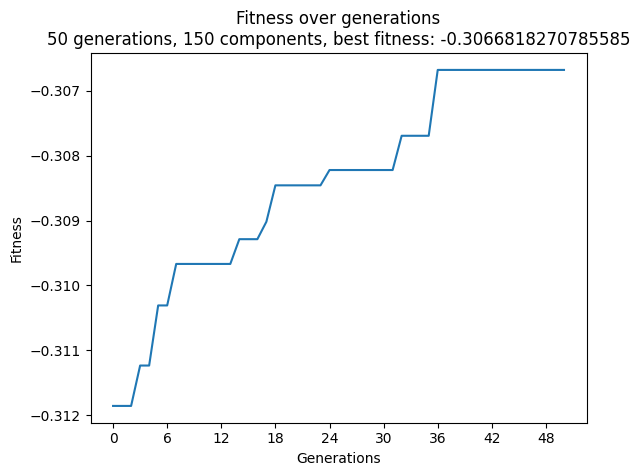

Generation 1 completed. Fitness: -0.3099360721603596, elapsed time(sec): 9826.951136112213.
Generation 2 completed. Fitness: -0.3099360721603596, elapsed time(sec): 10072.389469861984.
Generation 3 completed. Fitness: -0.3099360721603596, elapsed time(sec): 9949.922043323517.
Generation 4 completed. Fitness: -0.3099360721603596, elapsed time(sec): 9962.127542257309.
Generation 5 completed. Fitness: -0.3099360721603596, elapsed time(sec): 9837.760662078857.
Generation 6 completed. Fitness: -0.3099360721603596, elapsed time(sec): 10009.08439540863.
Generation 7 completed. Fitness: -0.3086451031765153, elapsed time(sec): 9854.566591024399.
Generation 8 completed. Fitness: -0.30751336777148397, elapsed time(sec): 10142.557805538177.
Generation 9 completed. Fitness: -0.30751336777148397, elapsed time(sec): 9910.692248821259.
Generation 10 completed. Fitness: -0.30751336777148397, elapsed time(sec): 9829.286973714828.
Generation 11 completed. Fitness: -0.30751336777148397, elapsed time(sec):

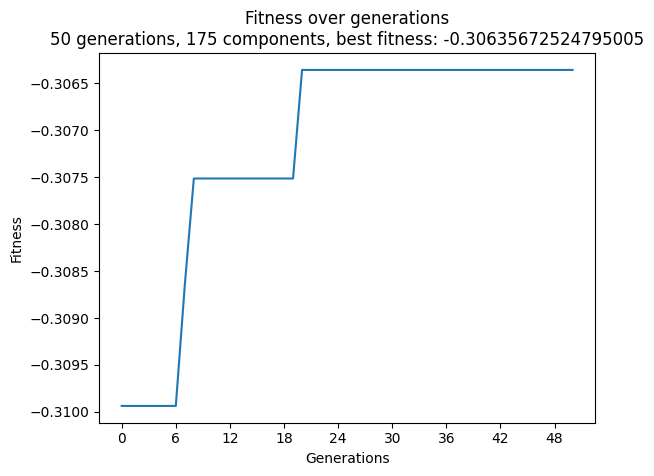

Generation 1 completed. Fitness: -0.31165909779940404, elapsed time(sec): 11197.906438112259.
Generation 2 completed. Fitness: -0.31165909779940404, elapsed time(sec): 11469.13061928749.
Generation 3 completed. Fitness: -0.3101343491049298, elapsed time(sec): 10771.121193647385.
Generation 4 completed. Fitness: -0.3101343491049298, elapsed time(sec): 11490.355608224869.
Generation 5 completed. Fitness: -0.3099719354201292, elapsed time(sec): 11050.747017145157.
Generation 6 completed. Fitness: -0.3099719354201292, elapsed time(sec): 11116.361793756485.
Generation 7 completed. Fitness: -0.309881377254109, elapsed time(sec): 11497.420446872711.
Generation 8 completed. Fitness: -0.3097601607217026, elapsed time(sec): 11132.713992118835.
Generation 9 completed. Fitness: -0.30819079951074785, elapsed time(sec): 11531.944726228714.
Generation 10 completed. Fitness: -0.30819079951074785, elapsed time(sec): 11355.627555847168.
Generation 11 completed. Fitness: -0.30819079951074785, elapsed tim

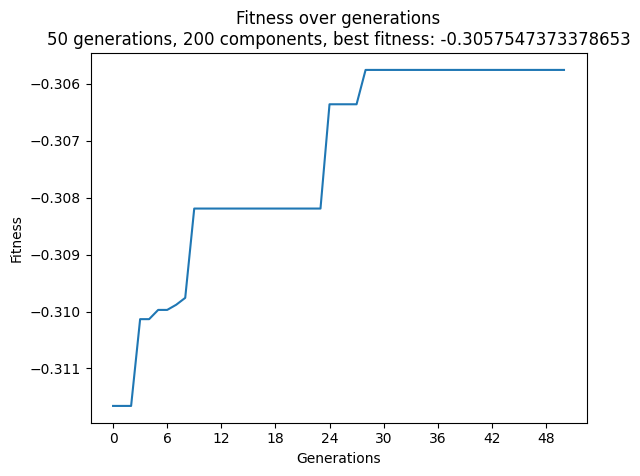

In [ ]:
pop_size = 40
#fixed_components = 120
crossp = 0.9
mutp = 0.0001

generations = 50
n_best = 20

all_solutions = {}

for fixed_components in [125]:
    ga = fixed_size_GA(pop_size, fixed_components, crossp, mutp)
    solution = ga.run(generations, n_best)[0]
    all_solutions[fixed_components] = solution

In [ ]:
def test_full_spectrum(model_full):
        X_full = model_full._X
        Y = model_full._Y
        trials = 100
        seeds =  np.random.choice(trials + 1, size=trials, replace=False)
        fitness_scores = []


        for i in range(trials):
            print(f"Trial {i}")
            X_train, X_test, Y_train, Y_test = train_test_split(
                X_full, Y, test_size=0.25, random_state=seeds[i])

            scaler = StandardScaler()
            X_train_scaled = scaler.fit_transform(X_train)
            X_test_scaled = scaler.transform(X_test)

            early_stopping = EarlyStopping(
            monitor='val_loss',
            min_delta=1e-4,       
            mode='auto',         
            patience=50,
            restore_best_weights=True, 
            )
    

            model = model_full._build_nn(filters=32, kernel_size=3)
            model.fit(X_train_scaled, Y_train, epochs=500, batch_size=32, validation_split=0.2,callbacks=[early_stopping],verbose=0)
            Y_pred = model.predict(X_test_scaled, verbose=0).flatten()

            score = model_full._NEGNRMSEPiqr(Y_test, Y_pred)
            print(score)
            fitness_scores.append(score)

            tf.keras.backend.clear_session()
            gc.collect()

        avg_score = np.mean(fitness_scores)
        print(f"Average fitness on full spectrum: {avg_score}")
        return avg_score

model_full = fixed_size_GA(N=1, m=530)
test_full_spectrum(model_full)

Trial 0
-0.2906769136862588
Trial 1
-0.27330303549884155
Trial 2
-0.28923235637815936
Trial 3
-0.35023531391338586
Trial 4
-0.32285649361152247
Trial 5
-0.30028035303606704
Trial 6
-0.3443246861618202
Trial 7
-0.2901529302783437
Trial 8
-0.2908140469933762
Trial 9
-0.2958654600918396
Trial 10
-0.3123488750426544
Trial 11
-0.33255963810883016
Trial 12
-0.2977457403226283
Trial 13
-0.2879103653387994
Trial 14
-0.2934951490479936
Trial 15
-0.3004332087665562
Trial 16
-0.32093395957710874
Trial 17
-0.3117230634155128
Trial 18
-0.32466559959239155
Trial 19
-0.3377382075729567
Trial 20
-0.32444925388208423
Trial 21
-0.3155293183739729
Trial 22
-0.30644423262885845
Trial 23
-0.31923596562919293
Trial 24
-0.3172935496311007
Trial 25
-0.3168886828941194
Trial 26
-0.35846526549581875
Trial 27
-0.32399136818427743
Trial 28
-0.3176369820484483
Trial 29
-0.31974004537533623
Trial 30
-0.30588804857726537
Trial 31
-0.31703153578886845
Trial 32
-0.30531993281714714
Trial 33
-0.29441754864679237
Trial 

np.float64(-0.3143409500436886)

In [ ]:
# fitness_by_components = {}
# time_by_components = {}

# for fixed_components, solution in all_solutions.items():
#     df = pd.read_excel("datasets/Dataset_2.xlsx",sheet_name="preproc")
#     X = (df.iloc[:,14:]).values
#     y = (df.iloc[:,7]).values


#     def NRMSEPiqr(observed_values, predicted_values):
#         # Calculate RMSEP
#         rmsep = np.sqrt(np.mean((observed_values - predicted_values) ** 2))
#         # Calculate Q1 (25th percentile) and Q3 (75th percentile)
#         Q1 = np.percentile(observed_values, 25)
#         Q3 = np.percentile(observed_values, 75)

#         # Calculate IQR
#         IQR = Q3 - Q1

#         return -rmsep/IQR


#     NRMSEPiqrscorer = make_scorer(NRMSEPiqr)



#     trials = 100
#     random_cv = np.random.seed(777)
#     seeds = np.random.choice(trials + 1, size=trials, replace= False)
#     ripartition = 0.25
#     final_results_nn = dict()


#     def build_nn(input_size, filters=32, kernel_size=3, dropout_rate=0.2, learning_rate=0.001):
#         inputs = tf.keras.Input(shape=(input_size,))
#         x = tf.keras.layers.Reshape((input_size, 1))(inputs)
#         x = tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu')(x)
#         x = tf.keras.layers.BatchNormalization()(x)
#         x = tf.keras.layers.Dropout(dropout_rate)(x)
#         x = tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu')(x)
#         x = tf.keras.layers.BatchNormalization()(x)
#         x = tf.keras.layers.GlobalAveragePooling1D()(x)
#         outputs = tf.keras.layers.Dense(1, activation='linear')(x)

#         model = tf.keras.Model(inputs=inputs, outputs=outputs)
#         model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mean_squared_error')
#         return model


#     NRMSE = []
#     total_time = 0

#     for i in range(trials):
#         X_train, X_test, Y_train, Y_test = train_test_split(
#             X[:, np.where(solution == 1)[0]], y, 
#             test_size=ripartition, random_state=seeds[i]
#         )
        
#         scaler = StandardScaler()
#         X_train_scaled = scaler.fit_transform(X_train)
#         X_test_scaled = scaler.transform(X_test)

#         model = build_nn(input_size=X_train_scaled.shape[1])
#         start_time = time.time()
#         model.fit(X_train_scaled, Y_train, epochs=5, batch_size=16, verbose=0)
#         elapsed_time = time.time() - start_time
        
#         Y_pred_nn = model.predict(X_test_scaled, verbose=0).flatten()
#         NRMSE.append(NRMSEPiqr(Y_test, Y_pred_nn))
#         total_time += elapsed_time
#         del model

#     fitness_by_components[fixed_components] = {
#         "mean": np.mean(NRMSE),
#         "var": np.var(NRMSE)
#     }
#     time_by_components[fixed_components] = total_time / trials


# components = sorted(fitness_by_components.keys())
# fitness_means = [fitness_by_components[c]["mean"] for c in components]
# fitness_vars = [fitness_by_components[c]["var"] for c in components]

# plt.figure(figsize=(10, 6))
# plt.errorbar(components, fitness_means, yerr=np.sqrt(fitness_vars), fmt='-o', capsize=5, label="Mean ± Std NRMSEPiqr")
# plt.xlabel("Fixed Components")
# plt.ylabel("NRMSEPiqr (negativo)")
# plt.title("Fitness (NRMSEPiqr) al variare dei fixed_components")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()

Starting 150 components
Starting 175 components
Starting 200 components


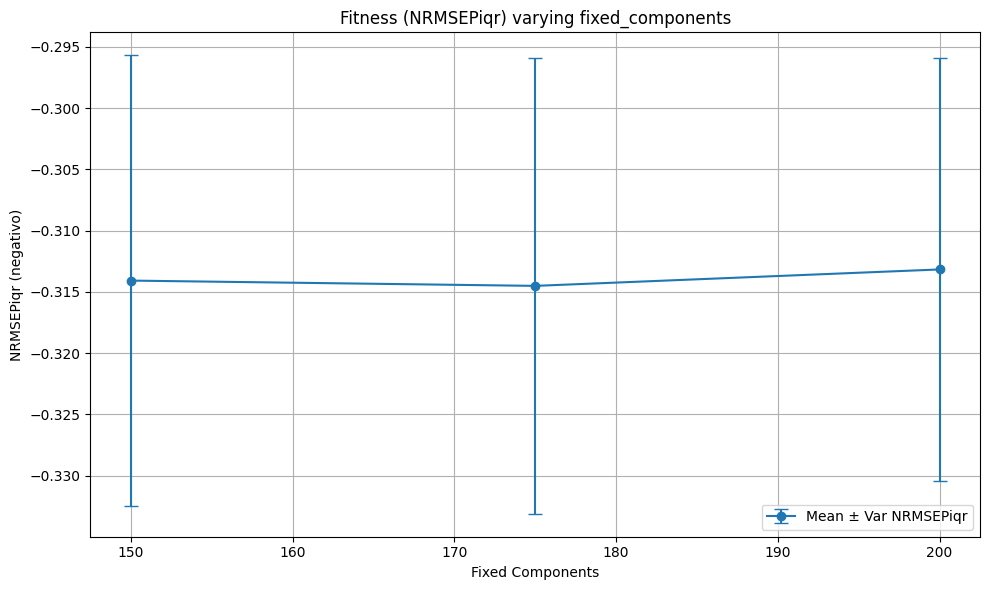

In [ ]:
fitness_by_components = {}
time_by_components = {}

for fixed_components, solution in all_solutions.items():
    print(f"Starting {fixed_components} components")
    df = pd.read_excel("datasets/Dataset_2.xlsx",sheet_name="preproc")
    X = (df.iloc[:,14:]).values
    y = (df.iloc[:,7]).values


    def NRMSEPiqr(observed_values, predicted_values):
        # Calculate RMSEP
        rmsep = np.sqrt(np.mean((observed_values - predicted_values) ** 2))
        # Calculate Q1 (25th percentile) and Q3 (75th percentile)
        Q1 = np.percentile(observed_values, 25)
        Q3 = np.percentile(observed_values, 75)

        # Calculate IQR
        IQR = Q3 - Q1

        return -rmsep/IQR


    NRMSEPiqrscorer = make_scorer(NRMSEPiqr)



    trials = 100
    random_cv = np.random.seed(777)
    seeds = np.random.choice(trials + 1, size=trials, replace= False)
    ripartition = 0.25
    final_results_nn = dict()


    def build_nn(input_size, filters=32, kernel_size=3, dropout_rate=0.2, learning_rate=0.001):

        '''
        inputs = tf.keras.Input(shape=(self._m,))
        x = tf.keras.layers.Reshape((self._m, 1))(inputs)
        x = tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu')(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Dropout(dropout_rate)(x)
        x = tf.keras.layers.Conv1D(filters=filters, kernel_size=kernel_size, activation='relu')(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.GlobalAveragePooling1D()(x)
        outputs = tf.keras.layers.Dense(1, activation='linear')(x)

        model = tf.keras.Model(inputs=inputs, outputs=outputs)
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='mean_squared_error')
        return model
        '''
        model = tf.keras.models.Sequential()
        model.add(tf.keras.layers.Input(shape=(input_size,)))
        model.add(tf.keras.layers.Reshape((input_size, 1)))
        # Convolutional layers
        model.add(tf.keras.layers.Conv1D(filters=32, kernel_size=kernel_size, padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.06), activation='elu'))
        model.add(tf.keras.layers.Conv1D(filters=64, kernel_size=kernel_size, padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.06), activation='elu'))
        # Fully connected layers
        model.add(tf.keras.layers.Flatten())
        model.add(tf.keras.layers.Dense(64, activation='elu'))
        model.add(tf.keras.layers.Dropout(0.2))
        model.add(tf.keras.layers.Dense(1, activation='linear'))
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mean_squared_error')
        return model


    NRMSE = []
    total_time = 0

    for i in range(trials):
        X_train, X_test, Y_train, Y_test = train_test_split(
            X[:, np.where(solution == 1)[0]], y, 
            test_size=ripartition, random_state=seeds[i]
        )
        
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)


        model = build_nn(input_size=X_train_scaled.shape[1])

        early_stopping = EarlyStopping(
            monitor='val_loss',
            min_delta=1e-4,       
            mode='auto',         
            patience=50,
            restore_best_weights=True, 
    )
        start_time = time.time()
        model.fit(X_train_scaled, Y_train, epochs=500, batch_size=32, verbose=0, validation_split=0.2, callbacks=[early_stopping])
        elapsed_time = time.time() - start_time
        
        Y_pred_nn = model.predict(X_test_scaled, verbose=0).flatten()
        NRMSE.append(NRMSEPiqr(Y_test, Y_pred_nn))
        total_time += elapsed_time
        del model

    fitness_by_components[fixed_components] = {
        "mean": np.mean(NRMSE),
        "var": np.var(NRMSE)
    }
    time_by_components[fixed_components] = total_time / trials


components = sorted(fitness_by_components.keys())
fitness_means = [fitness_by_components[c]["mean"] for c in components]
fitness_vars = [fitness_by_components[c]["var"] for c in components]

plt.figure(figsize=(10, 6))
plt.errorbar(components, fitness_means, yerr=np.sqrt(fitness_vars), fmt='-o', capsize=5, label="Mean ± Var NRMSEPiqr")
plt.xlabel("Fixed Components")
plt.ylabel("NRMSEPiqr (negativo)")
plt.title("Fitness (NRMSEPiqr) varying fixed_components")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
with open("Results_CNN.txt","w") as f:
    i = 0
    for fixed_components, solution in all_solutions.items():
        f.write("Components: " + str(fixed_components) + ", Mean NRMSEP: "  + str(-fitness_means[i]) +  ", Std: " + str(np.sqrt(fitness_vars[i]) ) + ", Mean Training Time(s): " + str(time_by_components[fixed_components]) + ", Bands: " + str(list(df.iloc[:,14:].columns[np.where(solution == 1)[0]])))
        f.write("\n")
        i+=1